In [36]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
from julia import Main
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm
from pygraphon.estimators.HistogramEstimator import HistogramEstimator
from pygraphon.estimators.utils.graphest_fastgreedy import _fastNormalizedBMLogLik

In [48]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.2,0.2],[0.2,0.8,0.2],[0.2,0.2,0.8]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
A = graphon.draw(rho = 0.7,n = 3*300, exchangeable=True)

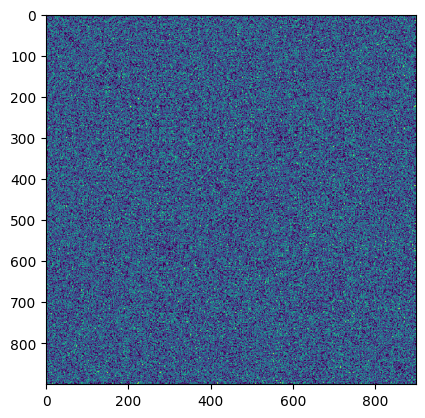

In [49]:
plt.imshow(A)

In [55]:
hist = HistogramEstimator()
hist.fit(graph= A, bandwidthHist= 1/3)
hist_approx = hist.get_graphon()
plt.imshow(hist_approx._get_edge_probabilities(99,False,True))
plt.colorbar()
plt.show()

Using Julia backend
'builtin_function_or_method' object has no attribute 'time'
julia not avaialble, falling back to python
Using Python backend


AttributeError: 'builtin_function_or_method' object has no attribute 'time'

Using Python backend


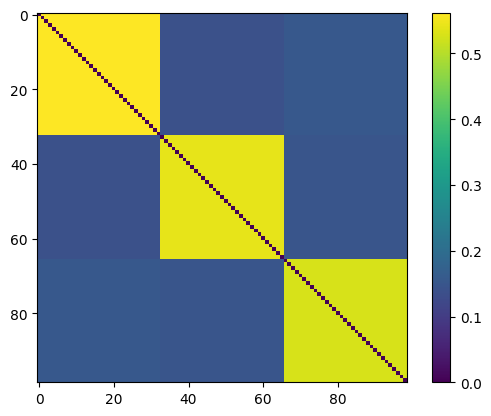

: 

In [ ]:
hist = HistogramEstimator(backend="python")
hist.fit(graph= A, bandwidthHist= 1/3)
hist_approx = hist.get_graphon()
plt.imshow(hist_approx._get_edge_probabilities(99,False,True))
plt.colorbar()
plt.show()

In [ ]:
from pygraphon.estimators.utils.nethist import nethist
labels, h, trace = nethist(A,h = 33,verbose=True, trace=True)

In [ ]:
plt.plot(trace[0])
plt.show()
plt.plot(trace[1])
plt.show()

In [ ]:
labels

In [ ]:
Main.include("../src/julia_backend/source/graphest_fastgreedy.jl")

In [ ]:
Main.log_likelihood(labels+1, A.astype(int),3) * 2 * A.shape[0] / np.sum(A)

In [ ]:
node_labels, theta, best_ll = Main.GreedyLLopt(A.astype(np.int64), 3,20000)

In [ ]:
best_ll

In [ ]:
Main.log_likelihood(node_labels, A.astype(int),3) * 2 * A.shape[0] / np.sum(A)

In [ ]:
node_labels

In [ ]:
labels

In [ ]:
for i in range(1,4):
    indices = np.where(node_labels == i)[0]
    print(i,np.unique(labels[indices], return_counts=True))

In [ ]:
my_dict = {3:2, 1:1, 2:0}


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(np.vectorize(my_dict.get)(node_labels), labels))

In [ ]:
theta

In [ ]:
labels